# Лабораторная работа №13: Fine-tuning diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Подготовить изображения/captions и fixed-seed baseline.
- Выполнить SD1.5 LoRA fine-tuning.
- Сравнить checkpoints, diversity и memorization.

## Теоретическая часть

Latent diffusion добавляет шум в latent space VAE, а U-Net предсказывает noise/velocity. LoRA адаптирует attention projections без изменения всех весов. Фиксированные seeds и prompts обязательны для сравнения checkpoints.

![Архитектура latent diffusion](https://raw.githubusercontent.com/CompVis/latent-diffusion/main/assets/modelfigure.png)


Latent diffusion обучает UNet предсказывать ε в пространстве VAE. LoRA добавляет обучаемые низкоранговые поправки к attention projections; VAE, text encoder и base UNet остаются замороженными. CLIP text similarity, разнообразие и ближайшая train генерация измеряют разные свойства и требуют ручного дополнения.

Для LoRA $W^{\prime}=W+BA$, где $B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r\ll\min(d,k)$. Noise-prediction минимизирует $\mathbb{E}_{x_0,\epsilon,t}\|\epsilon-\epsilon_\theta(z_t,t,c)\|_2^2$ на VAE-latents.

### Экспериментальный протокол

Основной эксперимент: SD 1.5 и 28 открытых реальных фотографий бабочек Wikimedia Commons при 512 px. `download_open_data.py` скачивает файлы и для каждого проверяет метаданные CC0-1.0 через Commons API, фиксирует страницу источника, URL лицензии и SHA256. Никакие файлы студента не требуются; `CV_LORA_DATA` задаёт альтернативный каталог с той же структурой metadata.jsonl. 3 независимых адаптера по 400 optimizer updates, checkpoint на 200/400; фиксированные held-out prompts и seeds. FAST_DEV_RUN: 256 px, один update, только smoke. Требуются GPU, Pillow, pip install diffusers transformers accelerate peft safetensors torchvision; на CPU не подменять обучение имитацией. CV_ARTIFACTS указывает на постоянный каталог Drive.

### Материалы

- [Diffusers LoRA training](https://huggingface.co/docs/diffusers/training/lora)
- [Latent Diffusion](https://arxiv.org/abs/2112.10752)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [8]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get("CV_LORA_DATA", "data/lab13"))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Лицензия и валидация изображений

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей.

**Результат.** Проверяемое состояние «Лицензия и валидация изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей» и его результат доступен следующему этапу.

In [9]:
!python3 '/content/download_open_data.py'

1/28 commons_00.jpg: 20230130-butterfly.jpg (135801 bytes)
2/28 commons_01.jpg: A Beautiful Black Butterfly.jpg (72201 bytes)
3/28 commons_02.jpg: A butterfly eating papaya, Location- Lakhimpur, Assam.jpg (124914 bytes)
4/28 commons_03.jpg: A butterfly on a purple flower.jpg (106346 bytes)
5/28 commons_04.jpg: Black and white butterfly near Shirahama.jpg (262645 bytes)
6/28 commons_05.jpg: Butterfly 51.jpg (90759 bytes)
7/28 commons_06.jpg: Butterfly Iguazu Falls.jpg (297914 bytes)
8/28 commons_07.jpg: Butterfly The Insect.jpg (354628 bytes)
9/28 commons_08.jpg: Butterfly at Jonanjima.jpg (93098 bytes)
10/28 commons_09.jpg: Butterfly at Wingham Wildlife Park Kent UK.jpg (84272 bytes)
11/28 commons_10.jpg: Butterfly by the water.jpg (152912 bytes)
12/28 commons_11.jpg: Butterfly enjoying with nature.jpg (101671 bytes)
13/28 commons_12.jpg: Butterfly from butterfly garden-lucknow zoo.jpg (497712 bytes)
14/28 commons_13.jpg: Butterfly hanging on leaf.jpg (163975 bytes)
15/28 commons_14.jp

In [10]:
from PIL import Image, UnidentifiedImageError
import hashlib
import json

metadata_path = DATA_ROOT / "metadata.jsonl"
if not metadata_path.exists():
    raise FileNotFoundError(
        f"Не найден файл {metadata_path}. Сначала запустите download_open_data.py."
    )

records = []
with metadata_path.open("r", encoding="utf-8") as f:
    for line_number, line in enumerate(f, 1):
        if line.strip():
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"Ошибка JSON в строке {line_number}: {e}")

required_fields = {"file_name", "text", "license", "license_url", "source_url", "sha256"}
validated, errors, seen_hashes = [], [], set()

for rec in records:
    missing = required_fields - set(rec)
    if missing:
        errors.append(f"{rec.get('file_name', 'unknown')}: отсутствуют поля {missing}")
        continue

    image_path = DATA_ROOT / rec["file_name"]
    if not image_path.is_file():
        errors.append(f"Нет файла: {image_path}")
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
        with Image.open(image_path) as img:
            rgb = img.convert("RGB")
            rgb.load()
            width, height = rgb.size

        if min(width, height) < 256:
            errors.append(f"{rec['file_name']}: слишком маленькое изображение {width}x{height}")
            continue

        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        if digest != rec["sha256"]:
            errors.append(f"{rec['file_name']}: SHA256 не совпадает с metadata.jsonl")
            continue
        if rec["license"] != "CC0-1.0":
            errors.append(f"{rec['file_name']}: неподходящая лицензия {rec['license']}")
            continue
        if "creativecommons.org/publicdomain/zero/1.0/" not in rec["license_url"]:
            errors.append(f"{rec['file_name']}: некорректная ссылка на CC0")
            continue
        if not rec["text"].strip():
            errors.append(f"{rec['file_name']}: пустой caption")
            continue
        if digest in seen_hashes:
            errors.append(f"{rec['file_name']}: дубликат изображения")
            continue

        seen_hashes.add(digest)
        validated.append({**rec, "width": width, "height": height, "verified_sha256": digest})

    except (OSError, UnidentifiedImageError, ValueError) as e:
        errors.append(f"{rec.get('file_name', 'unknown')}: ошибка изображения: {e}")

train_records = validated
validation_report = {
    "total_records": len(records),
    "valid_records": len(validated),
    "invalid_records": len(errors),
    "unique_images": len(seen_hashes),
    "license": "CC0-1.0",
    "errors": errors,
    "validated_files": [rec["file_name"] for rec in validated]
}
save_json("data_validation.json", validation_report)

print("Всего записей:", len(records))
print("Проверено изображений:", len(validated))
print("Уникальных изображений:", len(seen_hashes))
print("Ошибок:", len(errors))
print("Отчёт:", ARTIFACTS / "data_validation.json")
if errors:
    print("Первые ошибки:")
    for error in errors[:10]:
        print("-", error)
if len(train_records) < 10:
    raise RuntimeError("Недостаточно проверенных изображений для обучения.")

Всего записей: 28
Проверено изображений: 28
Уникальных изображений: 28
Ошибок: 0
Отчёт: artifacts/data_validation.json


### Отложенные текстовые запросы

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями.

**Результат.** Проверяемое состояние «Отложенные текстовые запросы» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями» и его результат доступен следующему этапу.

In [11]:
import re

def normalize_text(text):
    text = text.lower().strip()
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    return " ".join(text.split())

eval_prompts = [
    "a detailed macro photograph of a butterfly resting on a green leaf",
    "a colorful butterfly with open wings in a natural garden",
    "a close up photograph of a butterfly on a bright flower",
    "a small butterfly sitting on a tree branch",
    "a butterfly photographed in soft morning sunlight",
    "a detailed side view of a butterfly with patterned wings",
    "a butterfly resting among tropical green plants",
    "a wildlife photograph of a butterfly with folded wings"
]
train_captions = {normalize_text(rec["text"]) for rec in train_records}
normalized_prompts = [normalize_text(prompt) for prompt in eval_prompts]

if len(set(normalized_prompts)) != len(normalized_prompts):
    raise ValueError("В eval_prompts обнаружены повторы.")

overlap = set(normalized_prompts) & train_captions
if overlap:
    raise ValueError(f"Найдены точные совпадения с train captions: {overlap}")

eval_seeds = [42, 123, 456]
evaluation_config = {
    "prompts": eval_prompts,
    "seeds": eval_seeds,
    "num_prompts": len(eval_prompts),
    "num_seeds": len(eval_seeds),
    "total_generations_per_model": len(eval_prompts) * len(eval_seeds),
    "train_caption_overlap": len(overlap)
}
save_json("evaluation_config.json", evaluation_config)

print("Отложенных prompts:", len(eval_prompts))
print("Seeds:", eval_seeds)
print("Генераций на одну модель:", len(eval_prompts) * len(eval_seeds))
print("Совпадений с train captions:", len(overlap))
for i, prompt in enumerate(eval_prompts, 1):
    print(f"{i}. {prompt}")

Отложенных prompts: 8
Seeds: [42, 123, 456]
Генераций на одну модель: 24
Совпадений с train captions: 0
1. a detailed macro photograph of a butterfly resting on a green leaf
2. a colorful butterfly with open wings in a natural garden
3. a close up photograph of a butterfly on a bright flower
4. a small butterfly sitting on a tree branch
5. a butterfly photographed in soft morning sunlight
6. a detailed side view of a butterfly with patterned wings
7. a butterfly resting among tropical green plants
8. a wildlife photograph of a butterfly with folded wings


### Baseline SD на фиксированных запросах

*Вес: 1 балл.*

**Постановка.** Baseline до обучения и сопоставимый inference protocol позволяют увидеть фактический вклад LoRA. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds.

**Результат.** Проверяемое состояние «Baseline SD на фиксированных запросах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds» и его результат доступен следующему этапу.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (18 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Baseline изображений: 24
Каталог: artifacts/baseline


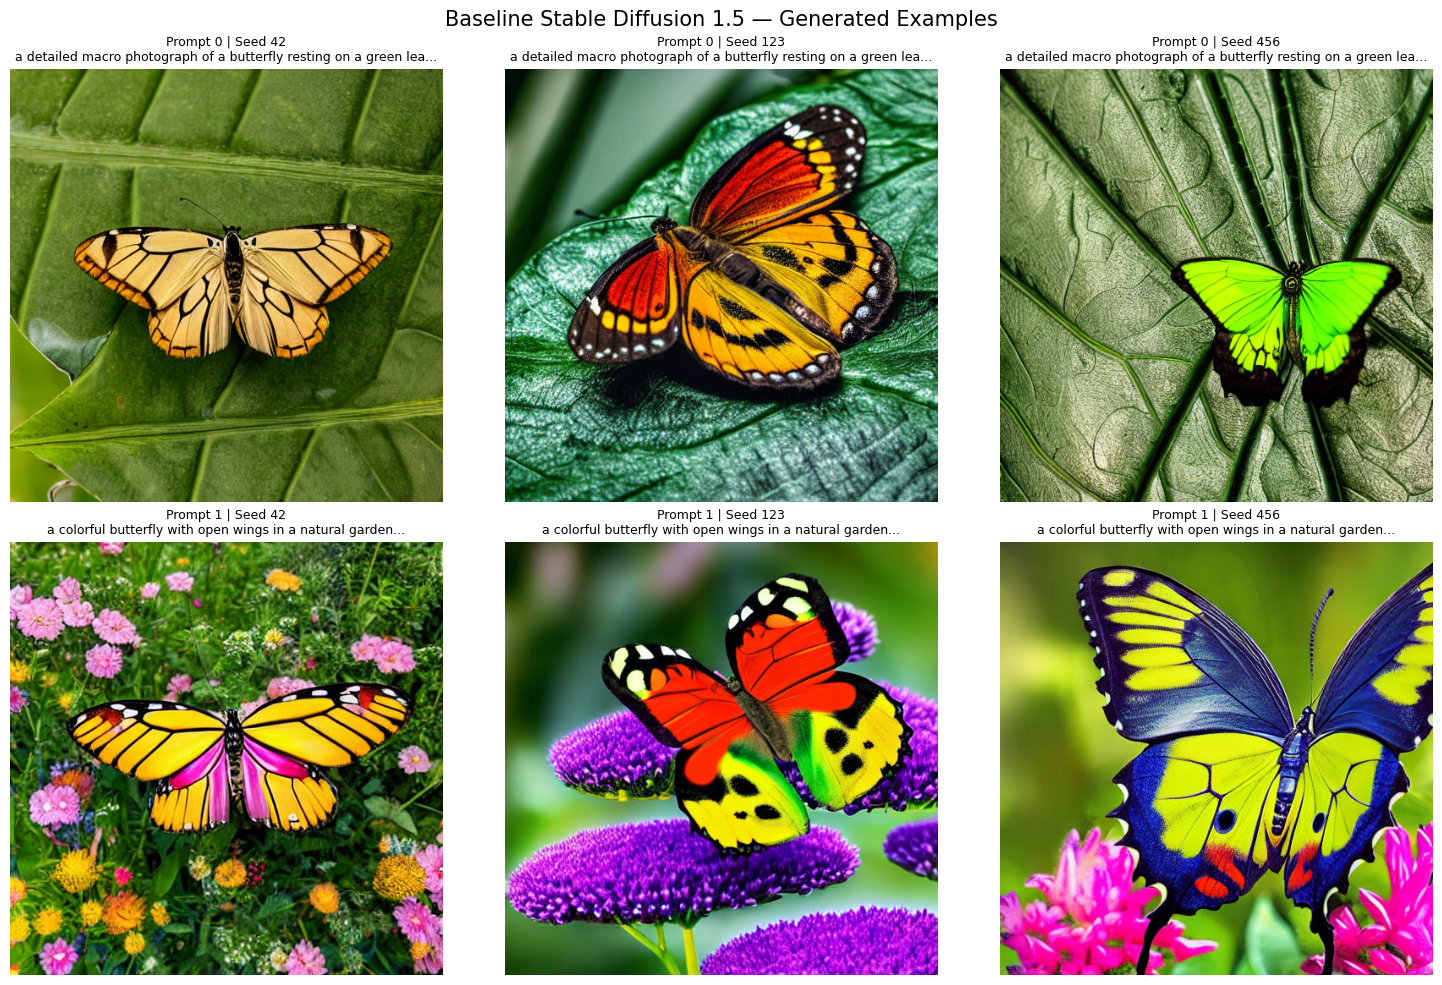

In [40]:
# Stable Diffusion 1.5 baseline: генерации до обучения LoRA
import gc
import torch
from diffusers import StableDiffusionPipeline

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
GEN_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if GEN_DEVICE != "cuda":
    raise RuntimeError("Для полного эксперимента требуется GPU. Включите GPU в Colab.")

if FAST_DEV_RUN:
    image_size = 256
    steps = 10
else:
    image_size = 512
    steps = 30

baseline_dir = ARTIFACTS / "baseline"
baseline_dir.mkdir(parents=True, exist_ok=True)

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16,
    safety_checker=None,
    requires_safety_checker=False
).to(GEN_DEVICE)

pipe.set_progress_bar_config(disable=False)
if hasattr(pipe, "enable_attention_slicing"):
    pipe.enable_attention_slicing()

baseline_records = []
for prompt_idx, prompt in enumerate(eval_prompts):
    for seed in eval_seeds:
        generator = torch.Generator(device=GEN_DEVICE).manual_seed(seed)
        result = pipe(
            prompt,
            height=image_size,
            width=image_size,
            num_inference_steps=steps,
            guidance_scale=7.5,
            generator=generator
        )
        image = result.images[0]
        filename = f"prompt_{prompt_idx:02d}_seed_{seed}.png"
        image.save(baseline_dir / filename)
        baseline_records.append({
            "model": "baseline",
            "prompt_id": prompt_idx,
            "prompt": prompt,
            "seed": seed,
            "image": str(baseline_dir / filename)
        })

with (ARTIFACTS / "baseline_generations.jsonl").open("w", encoding="utf-8") as f:
    for row in baseline_records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Baseline изображений:", len(baseline_records))
print("Каталог:", baseline_dir)
# Визуализация нескольких результатов Baseline SD
import matplotlib.pyplot as plt
from PIL import Image

num_examples = min(6, len(baseline_records))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i in range(num_examples):
    record = baseline_records[i]

    image = Image.open(record["image"]).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f"Prompt {record['prompt_id']} | Seed {record['seed']}\n"
        f"{record['prompt'][:65]}...",
        fontsize=9
    )
    axes[i].axis("off")

# Скрываем неиспользуемые области, если изображений меньше шести
for i in range(num_examples, len(axes)):
    axes[i].axis("off")

plt.suptitle("Baseline Stable Diffusion 1.5 — Generated Examples", fontsize=15)
plt.tight_layout()
plt.show()
# Освобождаем память перед обучением.
del pipe
gc.collect()
torch.cuda.empty_cache()

### Подготовка пар изображение–caption

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон.

**Результат.** Проверяемое состояние «Подготовка пар изображение–caption» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон» и его результат доступен следующему этапу.

In [13]:
# Dataset: изображение + caption, одинаковый preprocessing для всех конфигураций
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPTokenizer

tokenizer = CLIPTokenizer.from_pretrained(BASE_MODEL, subfolder="tokenizer")
TOKENIZER_MAX_LENGTH = tokenizer.model_max_length

class ButterflyDataset(Dataset):
    def __init__(self, records, tokenizer, size=512):
        self.records = records
        self.tokenizer = tokenizer
        self.size = size

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rec = self.records[index]
        path = DATA_ROOT / rec["file_name"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # Детерминированное преобразование: resize + center crop.
            w, h = image.size
            scale = self.size / min(w, h)
            new_w, new_h = round(w * scale), round(h * scale)
            image = image.resize((new_w, new_h), Image.Resampling.BICUBIC)
            left = (new_w - self.size) // 2
            top = (new_h - self.size) // 2
            image = image.crop((left, top, left + self.size, top + self.size))
            pixels = np.asarray(image, dtype=np.float32) / 127.5 - 1.0
            pixel_values = torch.from_numpy(pixels).permute(2, 0, 1).contiguous()

        tokens = self.tokenizer(
            rec["text"],
            max_length=TOKENIZER_MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "pixel_values": pixel_values,
            "input_ids": tokens.input_ids[0]
        }

train_dataset = ButterflyDataset(
    train_records, tokenizer, size=(256 if FAST_DEV_RUN else 512)
)
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

sample = train_dataset[0]
assert sample["pixel_values"].shape == (3, train_dataset.size, train_dataset.size)
assert sample["input_ids"].shape[0] == TOKENIZER_MAX_LENGTH
assert torch.isfinite(sample["pixel_values"]).all()
assert sample["pixel_values"].min() >= -1.001
assert sample["pixel_values"].max() <= 1.001

dataset_report = {
    "num_images": len(train_dataset),
    "image_size": train_dataset.size,
    "tokenizer_max_length": TOKENIZER_MAX_LENGTH,
    "pixel_min": float(sample["pixel_values"].min()),
    "pixel_max": float(sample["pixel_values"].max()),
    "caption_example": train_records[0]["text"]
}
save_json("dataset_report.json", dataset_report)
print(dataset_report)

{'num_images': 28, 'image_size': 512, 'tokenizer_max_length': 77, 'pixel_min': -1.0, 'pixel_max': 1.0, 'caption_example': 'a photo of sks butterfly, 20230130-butterfly'}


### Заморозка основы и конфигурации LoRA

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR.

**Результат.** Проверяемое состояние «Заморозка основы и конфигурации LoRA» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR» и его результат доступен следующему этапу.

In [14]:
# Три независимые конфигурации LoRA. Меняется rank и learning rate.
from peft import LoraConfig

TRAIN_STEPS = 1 if FAST_DEV_RUN else 400
CHECKPOINT_STEPS = [TRAIN_STEPS] if FAST_DEV_RUN else [200, 400]
TRAIN_CONFIGS = [
    {"name": "rank4_lr1e4", "rank": 4, "learning_rate": 1e-4},
    {"name": "rank8_lr5e5", "rank": 8, "learning_rate": 5e-5},
    {"name": "rank16_lr5e5", "rank": 16, "learning_rate": 5e-5},
]

training_plan = {
    "base_model": BASE_MODEL,
    "steps_per_config": TRAIN_STEPS,
    "checkpoint_steps": CHECKPOINT_STEPS,
    "batch_size": 1,
    "gradient_accumulation_steps": 1,
    "configs": TRAIN_CONFIGS,
    "target_modules": ["to_q", "to_k", "to_v", "to_out.0"],
    "seed": SEED
}
save_json("training_plan.json", training_plan)
print(json.dumps(training_plan, indent=2))

{
  "base_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "steps_per_config": 400,
  "checkpoint_steps": [
    200,
    400
  ],
  "batch_size": 1,
  "gradient_accumulation_steps": 1,
  "configs": [
    {
      "name": "rank4_lr1e4",
      "rank": 4,
      "learning_rate": 0.0001
    },
    {
      "name": "rank8_lr5e5",
      "rank": 8,
      "learning_rate": 5e-05
    },
    {
      "name": "rank16_lr5e5",
      "rank": 16,
      "learning_rate": 5e-05
    }
  ],
  "target_modules": [
    "to_q",
    "to_k",
    "to_v",
    "to_out.0"
  ],
  "seed": 42
}


### Оптимизация адаптеров и checkpoint

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге.

**Результат.** Проверяемое состояние «Оптимизация адаптеров и checkpoint» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге» и его результат доступен следующему этапу.

In [23]:
# Реальное обучение трёх LoRA-адаптеров с checkpoint на заданных шагах
import gc
import torch
import torch.nn.functional as F
from diffusers import AutoencoderKL, DDPMScheduler, UNet2DConditionModel
from transformers import CLIPTextModel
from peft import LoraConfig, get_peft_model_state_dict
from diffusers.utils import convert_state_dict_to_diffusers

if not torch.cuda.is_available():
    raise RuntimeError("Обучение SD 1.5 выполняется только на GPU.")

def train_one_lora(config):
    run_dir = ARTIFACTS / "lora" / config["name"]
    run_dir.mkdir(parents=True, exist_ok=True)

    # Каждый запуск начинает с одной и той же исходной SD 1.5.
    noise_scheduler = DDPMScheduler.from_pretrained(BASE_MODEL, subfolder="scheduler")
    vae = AutoencoderKL.from_pretrained(
        BASE_MODEL, subfolder="vae", torch_dtype=torch.float16
    ).to("cuda")
    text_encoder = CLIPTextModel.from_pretrained(
        BASE_MODEL, subfolder="text_encoder", torch_dtype=torch.float16
    ).to("cuda")
    unet = UNet2DConditionModel.from_pretrained(
        BASE_MODEL, subfolder="unet", torch_dtype=torch.float16
    ).to("cuda")

    vae.requires_grad_(False).eval()
    for param in unet.parameters():
      if param.requires_grad:
        param.data = param.data.float()
    text_encoder.requires_grad_(False).eval()
    unet.requires_grad_(False)

    lora_config = LoraConfig(
        r=config["rank"],
        lora_alpha=config["rank"],
        lora_dropout=0.0,
        init_lora_weights="gaussian",
        target_modules=["to_q", "to_k", "to_v", "to_out.0"]
    )
    unet.add_adapter(lora_config)

    trainable_params = [p for p in unet.parameters() if p.requires_grad]
    if not trainable_params:
        raise RuntimeError("LoRA не создала обучаемых параметров.")

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=config["learning_rate"],
        betas=(0.9, 0.999),
        weight_decay=1e-2
    )
    scaler = torch.amp.GradScaler("cuda", enabled=True)

    if hasattr(unet, "enable_gradient_checkpointing"):
        unet.enable_gradient_checkpointing()
    if hasattr(unet, "enable_xformers_memory_efficient_attention"):
        try:
            unet.enable_xformers_memory_efficient_attention()
        except Exception:
            pass

    unet.train()
    step = 0
    losses = []
    data_iter = iter(train_loader)
    started = time.time()

    while step < TRAIN_STEPS:
        try:
            batch = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            batch = next(data_iter)

        pixel_values = batch["pixel_values"].to(
            "cuda", dtype=torch.float16, non_blocking=True
        )
        input_ids = batch["input_ids"].to("cuda", non_blocking=True)

        with torch.no_grad():
            with torch.autocast("cuda", dtype=torch.float16):
                latents = vae.encode(pixel_values).latent_dist.sample()
                latents = latents * vae.config.scaling_factor
                encoder_hidden_states = text_encoder(input_ids)[0]

        noise = torch.randn_like(latents)
        timesteps = torch.randint(
            0, noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],), device="cuda"
        ).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            model_pred = unet(
                noisy_latents,
                timesteps,
                encoder_hidden_states
            ).sample

            prediction_type = getattr(
                noise_scheduler.config, "prediction_type", "epsilon"
            )
            if prediction_type == "epsilon":
                target = noise
            elif prediction_type == "v_prediction":
                target = noise_scheduler.get_velocity(latents, noise, timesteps)
            else:
                raise ValueError(f"Неизвестный prediction_type: {prediction_type}")

            loss = F.mse_loss(
                model_pred.float(), target.float(), reduction="mean"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        step += 1
        losses.append(float(loss.detach().cpu()))

        if step in CHECKPOINT_STEPS:
            checkpoint_dir = run_dir / f"checkpoint-{step}"
            adapter_dir = checkpoint_dir / "adapter"
            adapter_dir.mkdir(parents=True, exist_ok=True)

            # Сохраняем portable LoRA weights в формате Diffusers.
            lora_state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
            from diffusers import StableDiffusionPipeline
            StableDiffusionPipeline.save_lora_weights(
                save_directory=str(adapter_dir),
                unet_lora_layers=lora_state,
                safe_serialization=True
            )

            # Optimizer/scaler нужны для продолжения обучения.
            torch.save({
                "step": step,
                "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(),
                "loss": losses[-1],
                "config": config
            }, checkpoint_dir / "training_state.pt")

            save_json(
                f"lora/{config['name']}/checkpoint-{step}/metrics.json",
                {
                    "step": step,
                    "loss": losses[-1],
                    "mean_loss_so_far": float(np.mean(losses)),
                    "elapsed_seconds": time.time() - started,
                    "config": config
                }
            )
            print(
                f"{config['name']}: checkpoint {step}/{TRAIN_STEPS}, "
                f"loss={losses[-1]:.5f}"
            )

    summary = {
        "name": config["name"],
        "rank": config["rank"],
        "learning_rate": config["learning_rate"],
        "steps": step,
        "final_loss": losses[-1],
        "mean_loss": float(np.mean(losses)),
        "elapsed_seconds": time.time() - started
    }
    save_json(f"lora/{config['name']}/training_summary.json", summary)

    del optimizer, unet, vae, text_encoder, noise_scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()
    return summary

training_summaries = []
for cfg in TRAIN_CONFIGS:
    print("\nЗапуск:", cfg["name"])
    training_summaries.append(train_one_lora(cfg))

save_json("training_summaries.json", training_summaries)
print(json.dumps(training_summaries, indent=2))


Запуск: rank4_lr1e4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

rank4_lr1e4: checkpoint 200/400, loss=0.03290
rank4_lr1e4: checkpoint 400/400, loss=0.12305

Запуск: rank8_lr5e5


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

rank8_lr5e5: checkpoint 200/400, loss=0.22044
rank8_lr5e5: checkpoint 400/400, loss=0.00517

Запуск: rank16_lr5e5


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

rank16_lr5e5: checkpoint 200/400, loss=0.30903
rank16_lr5e5: checkpoint 400/400, loss=0.11209
[
  {
    "name": "rank4_lr1e4",
    "rank": 4,
    "learning_rate": 0.0001,
    "steps": 400,
    "final_loss": 0.12305082380771637,
    "mean_loss": 0.15367890830093528,
    "elapsed_seconds": 236.28919172286987
  },
  {
    "name": "rank8_lr5e5",
    "rank": 8,
    "learning_rate": 5e-05,
    "steps": 400,
    "final_loss": 0.005174493882805109,
    "mean_loss": 0.1459059041843284,
    "elapsed_seconds": 223.49864602088928
  },
  {
    "name": "rank16_lr5e5",
    "rank": 16,
    "learning_rate": 5e-05,
    "steps": 400,
    "final_loss": 0.11208543181419373,
    "mean_loss": 0.1467487553897081,
    "elapsed_seconds": 223.74706649780273
  }
]


In [20]:
!pip install torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 15.3 MB/s  0:00:00


### Признаки CLIP для независимой оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings.

**Результат.** Проверяемое состояние «Признаки CLIP для независимой оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings» и его результат доступен следующему этапу.

In [31]:
# CLIP: нормализованные embeddings изображений и текста
import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_ID, torch_dtype=torch.float16
).to("cuda").eval()
clip_model.requires_grad_(False)

@torch.no_grad()
def get_clip_image_embeddings(images, batch_size=16):
    all_features = []
    for start in range(0, len(images), batch_size):
        batch_images = images[start:start + batch_size]
        inputs = clip_processor(
            images=batch_images, return_tensors="pt"
        ).to("cuda")
        outputs = clip_model.vision_model(
        pixel_values=inputs["pixel_values"]
        )
        features = clip_model.visual_projection(
        outputs.pooler_output
        )
        features = F.normalize(features.float(), dim=-1)
        all_features.append(features.cpu())
    return torch.cat(all_features, dim=0)

@torch.no_grad()
def get_clip_text_embeddings(texts, batch_size=16):
    all_features = []
    clip_model.eval()
    clip_model.to("cuda")
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        inputs = clip_processor(
            text=batch,
            padding=True,
            truncation=True,
            return_tensors="pt"
        )
        inputs = {
            key: value.to("cuda")
            for key, value in inputs.items()
        }
        with torch.no_grad():
            outputs = clip_model.text_model(
                input_ids=inputs["input_ids"],
                attention_mask=inputs.get("attention_mask")
            )
            features = clip_model.text_projection(
                outputs.pooler_output
            )
            features = F.normalize(
                features.float(),
                dim=-1
            )
        all_features.append(features.cpu())
    return torch.cat(all_features, dim=0)

print("CLIP загружен:", CLIP_MODEL_ID)
print("Размерность embeddings:", clip_model.config.projection_dim)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP загружен: openai/clip-vit-base-patch32
Размерность embeddings: 512


### Поиск ближайших обучающих изображений

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки.

**Результат.** Проверяемое состояние «Поиск ближайших обучающих изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки» и его результат доступен следующему этапу.

In [32]:
# Эмбеддинги реальных train изображений и список checkpoints для оценки
from PIL import Image

train_images = []
train_image_names = []
for rec in train_records:
    with Image.open(DATA_ROOT / rec["file_name"]) as im:
        train_images.append(im.convert("RGB").copy())
    train_image_names.append(rec["file_name"])

train_image_embeddings = get_clip_image_embeddings(train_images)
assert train_image_embeddings.shape[0] == len(train_records)

torch.save({
    "embeddings": train_image_embeddings,
    "file_names": train_image_names
}, ARTIFACTS / "train_clip_embeddings.pt")

checkpoint_manifest = []
for cfg in TRAIN_CONFIGS:
    for step in CHECKPOINT_STEPS:
        adapter_dir = ARTIFACTS / "lora" / cfg["name"] / f"checkpoint-{step}" / "adapter"
        if adapter_dir.exists():
            checkpoint_manifest.append({
                "model": cfg["name"],
                "step": step,
                "adapter_dir": str(adapter_dir)
            })

if len(checkpoint_manifest) == 0:
    raise RuntimeError("Не найдены LoRA checkpoints. Сначала выполните ячейку 18.")

save_json("checkpoint_manifest.json", checkpoint_manifest)
print("Train embeddings:", tuple(train_image_embeddings.shape))
print("Checkpoints для оценки:", len(checkpoint_manifest))
for item in checkpoint_manifest:
    print(item)

Train embeddings: (28, 512)
Checkpoints для оценки: 6
{'model': 'rank4_lr1e4', 'step': 200, 'adapter_dir': 'artifacts/lora/rank4_lr1e4/checkpoint-200/adapter'}
{'model': 'rank4_lr1e4', 'step': 400, 'adapter_dir': 'artifacts/lora/rank4_lr1e4/checkpoint-400/adapter'}
{'model': 'rank8_lr5e5', 'step': 200, 'adapter_dir': 'artifacts/lora/rank8_lr5e5/checkpoint-200/adapter'}
{'model': 'rank8_lr5e5', 'step': 400, 'adapter_dir': 'artifacts/lora/rank8_lr5e5/checkpoint-400/adapter'}
{'model': 'rank16_lr5e5', 'step': 200, 'adapter_dir': 'artifacts/lora/rank16_lr5e5/checkpoint-200/adapter'}
{'model': 'rank16_lr5e5', 'step': 400, 'adapter_dir': 'artifacts/lora/rank16_lr5e5/checkpoint-400/adapter'}


### Парные генерации и измеримые показатели

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA.

**Результат.** Проверяемое состояние «Парные генерации и измеримые показатели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA» и его результат доступен следующему этапу.

In [33]:
# Парные генерации: baseline и LoRA checkpoints на одинаковых prompts/seeds
import gc
import csv
import torch
import torch.nn.functional as F
from PIL import Image
from diffusers import StableDiffusionPipeline

EVAL_STEPS = 10 if FAST_DEV_RUN else 30
eval_size = 256 if FAST_DEV_RUN else 512
evaluation_dir = ARTIFACTS / "evaluation_images"
evaluation_dir.mkdir(parents=True, exist_ok=True)

def load_rgb(path):
    with Image.open(path) as im:
        return im.convert("RGB").copy()

def evaluate_image_group(records, model_label):
    paths = [r["image"] for r in records]
    images = [load_rgb(p) for p in paths]
    image_emb = get_clip_image_embeddings(images)
    text_emb = get_clip_text_embeddings([r["prompt"] for r in records])

    text_sim = (image_emb * text_emb).sum(dim=1)
    # Среднее попарное расстояние cosine для diversity.
    if len(image_emb) > 1:
        sim_matrix = image_emb @ image_emb.T
        upper = sim_matrix[torch.triu(
            torch.ones_like(sim_matrix, dtype=torch.bool), diagonal=1
        )]
        diversity = float((1.0 - upper).mean())
    else:
        diversity = 0.0

    nearest_sim, nearest_idx = (image_emb @ train_image_embeddings.T).max(dim=1)
    rows = []
    for i, rec in enumerate(records):
        rows.append({
            "model": model_label,
            "prompt_id": rec["prompt_id"],
            "prompt": rec["prompt"],
            "seed": rec["seed"],
            "image": rec["image"],
            "clip_text_similarity": float(text_sim[i]),
            "nearest_train_similarity": float(nearest_sim[i]),
            "nearest_train_file": train_image_names[int(nearest_idx[i])],
            "diversity_group_mean": diversity
        })
    return rows

all_metric_rows = []

# Baseline images were generated before training and contain no LoRA.
baseline_rows = evaluate_image_group(baseline_records, "baseline")
all_metric_rows.extend(baseline_rows)

for item in checkpoint_manifest:
    label = f"{item['model']}_step{item['step']}"
    print("\nОценка:", label)

    pipe = StableDiffusionPipeline.from_pretrained(
        BASE_MODEL,
        torch_dtype=torch.float16,
        safety_checker=None,
        requires_safety_checker=False
    ).to("cuda")
    pipe.set_progress_bar_config(disable=True)
    pipe.load_lora_weights(item["adapter_dir"])

    generated = []
    for prompt_idx, prompt in enumerate(eval_prompts):
        for seed in eval_seeds:
            generator = torch.Generator(device="cuda").manual_seed(seed)
            image = pipe(
                prompt,
                height=eval_size,
                width=eval_size,
                num_inference_steps=EVAL_STEPS,
                guidance_scale=7.5,
                generator=generator
            ).images[0]

            filename = f"{label}_p{prompt_idx:02d}_s{seed}.png"
            path = evaluation_dir / filename
            image.save(path)
            generated.append({
                "model": label,
                "prompt_id": prompt_idx,
                "prompt": prompt,
                "seed": seed,
                "image": str(path)
            })

    all_metric_rows.extend(evaluate_image_group(generated, label))
    del pipe
    gc.collect()
    torch.cuda.empty_cache()

metrics_path = ARTIFACTS / "evaluation_metrics.csv"
with metrics_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(all_metric_rows[0].keys()))
    writer.writeheader()
    writer.writerows(all_metric_rows)

with (ARTIFACTS / "evaluation_metrics.jsonl").open("w", encoding="utf-8") as f:
    for row in all_metric_rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

# Сводка по моделям
summary = {}
for row in all_metric_rows:
    summary.setdefault(row["model"], []).append(row)

summary_rows = []
for model_name, rows in summary.items():
    summary_rows.append({
        "model": model_name,
        "n": len(rows),
        "mean_clip_text_similarity": float(np.mean([x["clip_text_similarity"] for x in rows])),
        "mean_nearest_train_similarity": float(np.mean([x["nearest_train_similarity"] for x in rows])),
        "diversity_group_mean": float(np.mean([x["diversity_group_mean"] for x in rows]))
    })

save_json("evaluation_summary.json", summary_rows)
print("Метрики сохранены:", metrics_path)
print(json.dumps(summary_rows, indent=2))


Оценка: rank4_lr1e4_step200


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new



Оценка: rank4_lr1e4_step400


... (16 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Метрики сохранены: artifacts/evaluation_metrics.csv
[
  {
    "model": "baseline",
    "n": 24,
    "mean_clip_text_similarity": 0.31214746460318565,
    "mean_nearest_train_similarity": 0.8763212462266287,
    "diversity_group_mean": 0.13708658516407013
  },
  {
    "model": "rank4_lr1e4_step200",
    "n": 24,
    "mean_clip_text_similarity": 0.3157160443564256,
    "mean_nearest_train_similarity": 0.8715789665778478,
    "diversity_group_mean": 0.14675535261631012
  },
  {
    "model": "rank4_lr1e4_step400",
    "n": 24,
    "mean_clip_text_similarity": 0.3170810391505559,
    "mean_nearest_train_similarity": 0.8707257807254791,
    "diversity_group_mean": 0.15589691698551178
  },
  {
    "model": "rank8_lr5e5_step200",
    "n": 24,
    "mean_clip_text_similarity": 0.3139839159945647,
    "mean_nearest_train_similarity": 0.8839239502946535,
    "diversity_group_mean": 0.131609246134758
  },
  {
    "model": "rank8_lr5e5_step400",
    "n": 24,
    "mean_clip_text_similarity": 0.313638

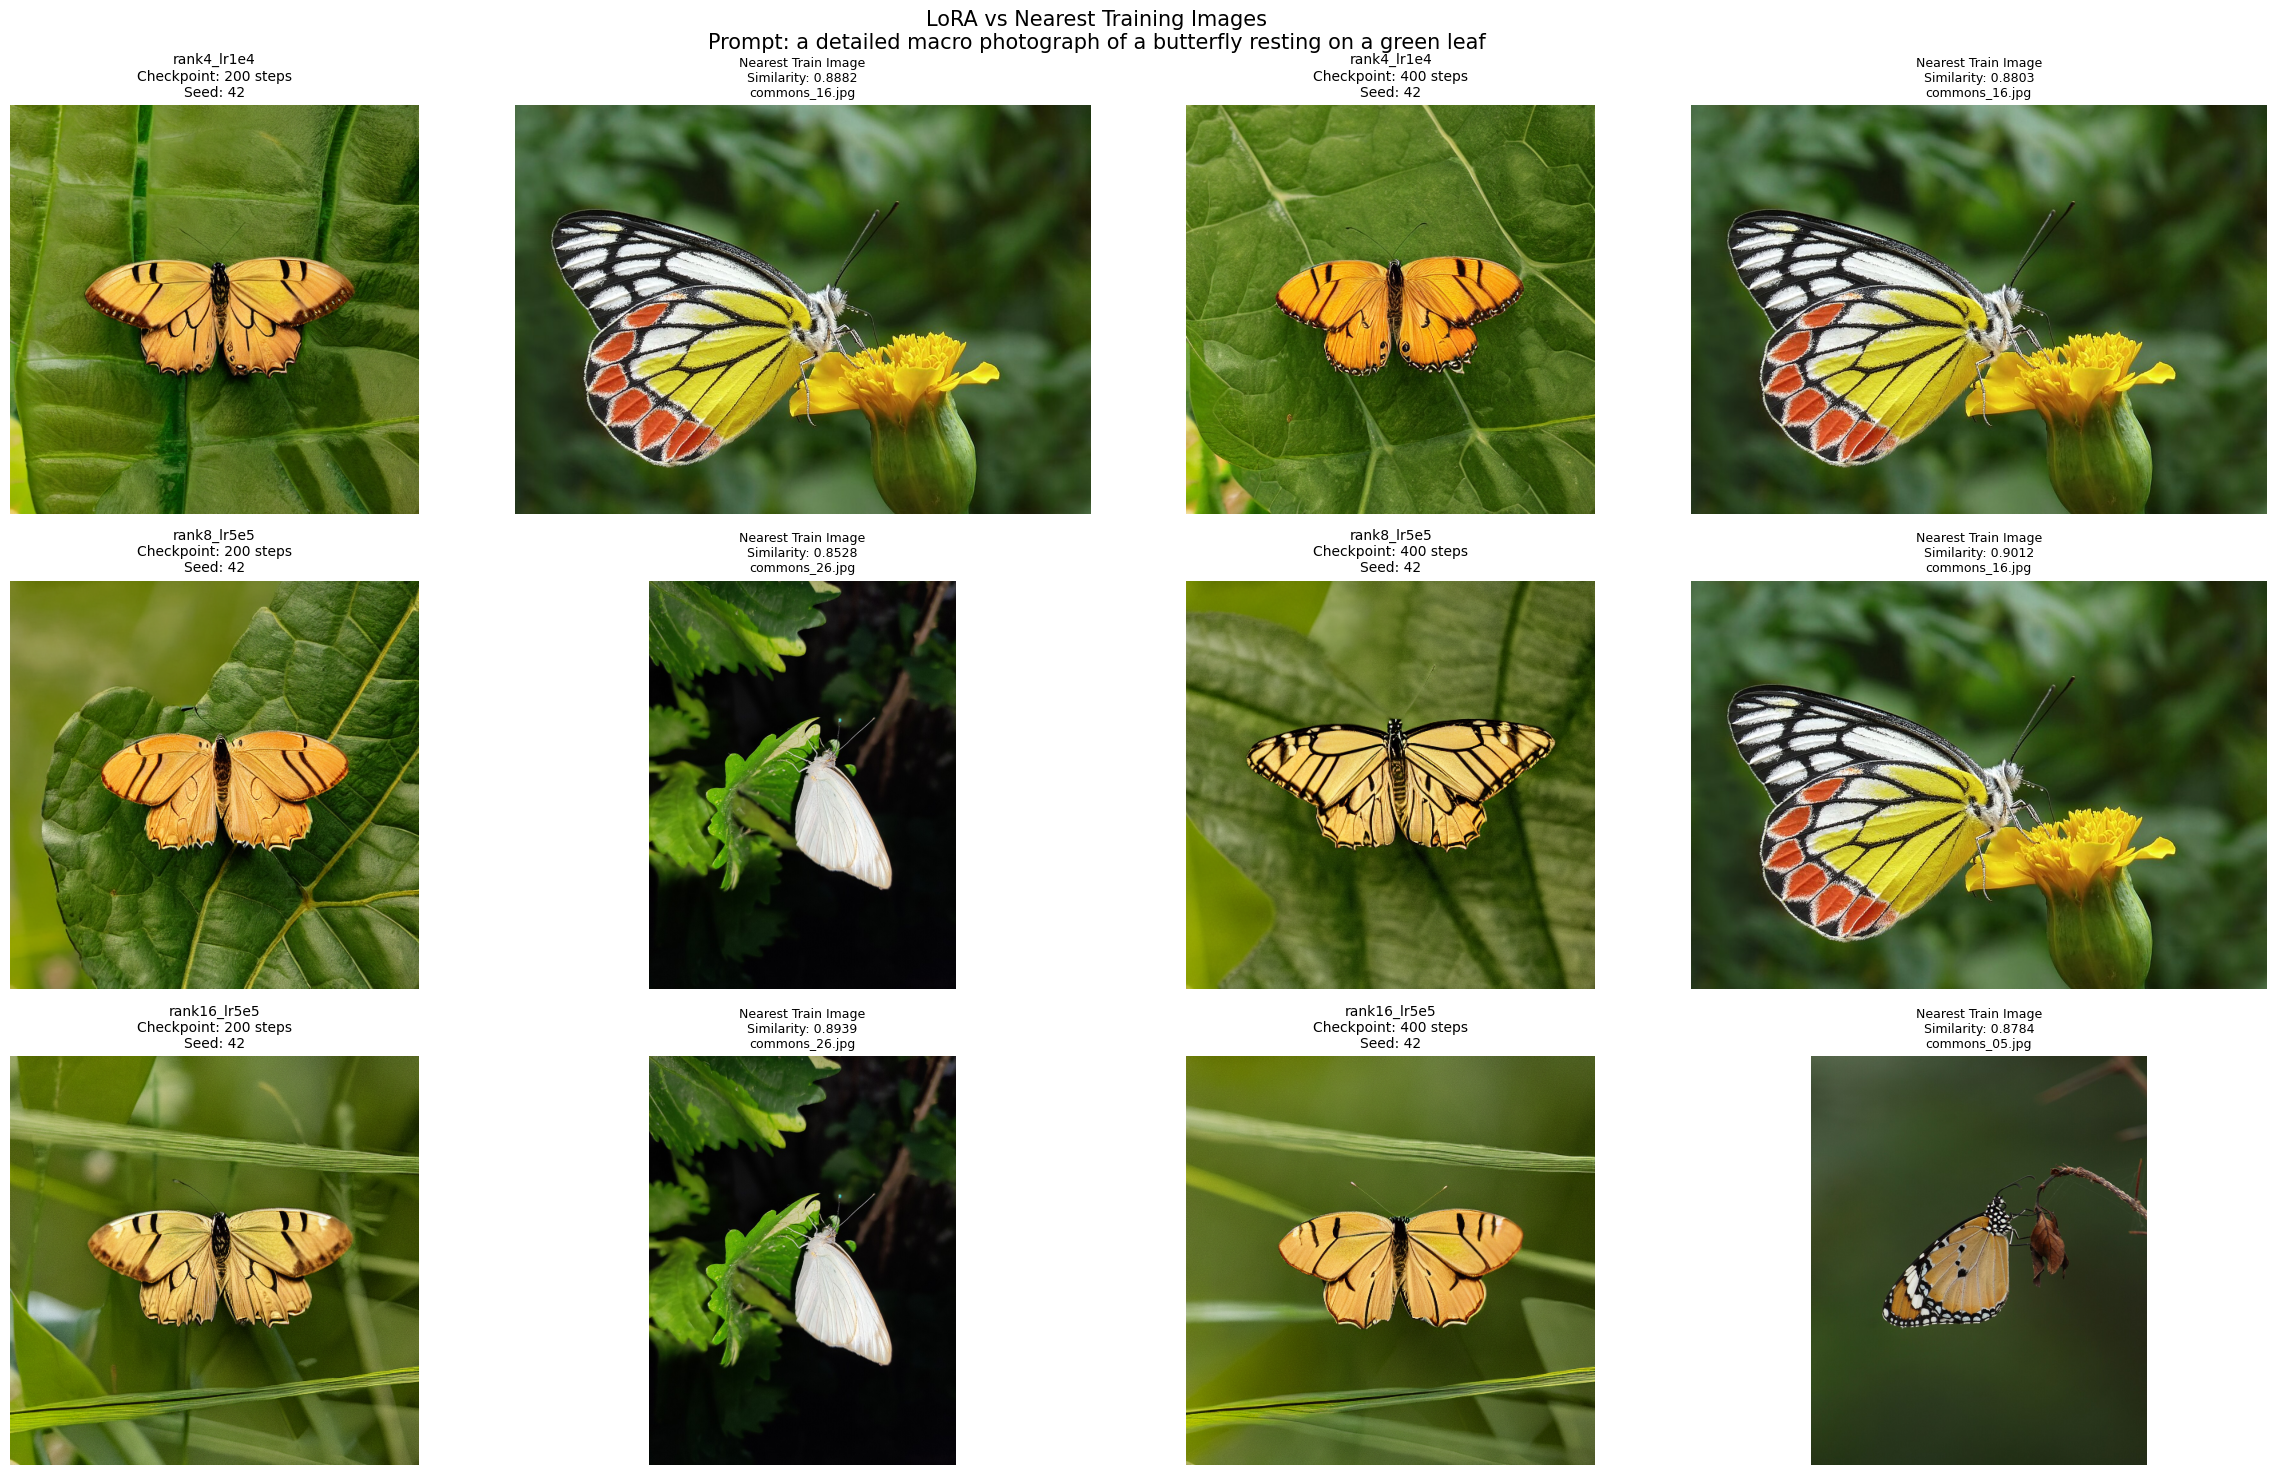

In [43]:
# Визуализация LoRA checkpoints и ближайших Train изображений

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from pathlib import Path

preview_seed = eval_seeds[0]
preview_prompt = eval_prompts[0]

n_rows = len(TRAIN_CONFIGS)
n_cols = len(CHECKPOINT_STEPS)

fig, axes = plt.subplots(
    n_rows,
    n_cols * 2,
    figsize=(12 * n_cols, 5 * n_rows),
    squeeze=False
)

# Получаем embeddings для выбранных генераций
for item in checkpoint_manifest:
    model_name = item["model"]
    step = item["step"]

    label = f"{model_name}_step{step}"
    filename = f"{label}_p00_s{preview_seed}.png"
    image_path = evaluation_dir / filename

    if not image_path.exists():
        print("Не найден файл:", image_path)
        continue

    # Находим ближайшее изображение из Train Dataset
    generated_image = Image.open(image_path).convert("RGB")

    generated_embedding = get_clip_image_embeddings(
        [generated_image]
    )

    similarities = F.cosine_similarity(
        generated_embedding,
        train_image_embeddings,
        dim=1
    )

    nearest_idx = similarities.argmax().item()
    nearest_similarity = similarities[nearest_idx].item()

    nearest_image_path = (
        DATA_ROOT / train_image_names[nearest_idx]
    )

    nearest_image = Image.open(
        nearest_image_path
    ).convert("RGB")

    # Индексы строки и столбцов
    row_idx = next(
        i for i, cfg in enumerate(TRAIN_CONFIGS)
        if cfg["name"] == model_name
    )

    col_idx = next(
        i for i, checkpoint_step in enumerate(CHECKPOINT_STEPS)
        if checkpoint_step == step
    )

    left_col = col_idx * 2

    # Генерация LoRA
    axes[row_idx, left_col].imshow(generated_image)
    axes[row_idx, left_col].set_title(
        f"{model_name}\n"
        f"Checkpoint: {step} steps\n"
        f"Seed: {preview_seed}",
        fontsize=10
    )
    axes[row_idx, left_col].axis("off")

    # Ближайшее обучающее изображение
    axes[row_idx, left_col + 1].imshow(nearest_image)
    axes[row_idx, left_col + 1].set_title(
        f"Nearest Train Image\n"
        f"Similarity: {nearest_similarity:.4f}\n"
        f"{train_image_names[nearest_idx]}",
        fontsize=9
    )
    axes[row_idx, left_col + 1].axis("off")

plt.suptitle(
    f"LoRA vs Nearest Training Images\n"
    f"Prompt: {preview_prompt}",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Слепая таблица оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов.

**Результат.** Проверяемое состояние «Слепая таблица оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов» и его результат доступен следующему этапу.

In [39]:
# Слепая таблица для экспертной оценки
import csv
import random

blind_rows = []
blind_key = []
for row in all_metric_rows:
    blind_id = f"IMG-{len(blind_rows)+1:04d}"
    blind_rows.append({
        "blind_id": blind_id,
        "image_path": row["image"],
        "prompt": row["prompt"],
        "seed": row["seed"],
        "realism_1_5": "",
        "butterfly_fidelity_1_5": "",
        "visual_quality_1_5": "",
        "comments": ""
    })
    blind_key.append({
        "blind_id": blind_id,
        "model": row["model"],
        "prompt_id": row["prompt_id"],
        "image_path": row["image"]
    })

random.Random(SEED).shuffle(blind_rows)
blind_csv = ARTIFACTS / "blind_expert_evaluation.csv"
with blind_csv.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(blind_rows[0].keys()))
    writer.writeheader()
    writer.writerows(blind_rows)

# Ключ хранится отдельно и не передаётся экспертам.
save_json("blind_key.json", blind_key)

print("Слепая таблица:", blind_csv)
print("Изображений для экспертной оценки:", len(blind_rows))
print("Ключ соответствия сохранён отдельно:", ARTIFACTS / "blind_key.json")

blind_rows[0]

Слепая таблица: artifacts/blind_expert_evaluation.csv
Изображений для экспертной оценки: 168
Ключ соответствия сохранён отдельно: artifacts/blind_key.json


{'blind_id': 'IMG-0019',
 'image_path': 'artifacts/baseline/prompt_06_seed_42.png',
 'prompt': 'a butterfly resting among tropical green plants',
 'seed': 42,
 'realism_1_5': '',
 'butterfly_fidelity_1_5': '',
 'visual_quality_1_5': '',
 'comments': ''}

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.